# 08 · Ciencias de la vida: biología y medicina

Python es el lenguaje principal de la biología computacional y de la ciencia de datos médica. Este módulo usa
tres bibliotecas maduras en problemas realistas: **Biopython** para secuencias y evolución, **lifelines** para
el análisis de supervivencia de un ensayo clínico real y **scikit-learn** para un modelo de diagnóstico.

> Son ejemplos docentes, no consejo médico ni herramientas clínicas validadas.

**Aprenderás**
1. Secuencias de ADN y de proteínas: transcripción, traducción, contenido de GC, marcos de lectura
2. Simular la evolución y recuperarla con alineamiento de secuencias
3. Construir un árbol genealógico (filogenia) a partir de distancias entre secuencias
4. Análisis de supervivencia: curvas de Kaplan-Meier, la prueba log-rank y la regresión de Cox en un ensayo de cáncer de mama
5. Un clasificador de diagnóstico: validación cruzada, curvas ROC y elegir un umbral según la sensibilidad

## 1. Secuencias con Biopython
Un gen es una secuencia de ADN; la célula lo copia a ARN (*transcripción*) y lee el ARN de tres en tres letras
(*codones*) para construir una proteína (*traducción*). Diseñamos un gen para una proteína corta y lo pasamos
por todo el proceso.

In [1]:
from Bio.Seq import Seq
from Bio.SeqUtils import gc_fraction
from Bio.Data import CodonTable
import random

random.seed(7)
protein = "MALWMRLLPLLALLALWGPDPAAA"      # un tramo tipo péptido señal, 24 aminoácidos
table = CodonTable.unambiguous_dna_by_id[1]   # el código genético estándar
codons_for = {}
for codon, aa in table.forward_table.items():
    codons_for.setdefault(aa, []).append(codon)

gene = Seq("".join(random.choice(codons_for[aa]) for aa in protein) + "TAA")   # retrotraducir + codón de parada
print("ADN      :", gene)
print("ARN      :", gene.transcribe())
print("proteína :", gene.translate(to_stop=True), "| coincide con el diseño:", str(gene.translate(to_stop=True)) == protein)
print("contenido GC:", round(gc_fraction(gene), 3), "| complementaria inversa:", gene.reverse_complement()[:24], "...")

ADN      : ATGGCCCTCTGGATGAGATTACTTCCTCTATTGGCTTTACTCGCGTTATGGGGTCCGGATCCTGCCGCTGCGTAA
ARN      : AUGGCCCUCUGGAUGAGAUUACUUCCUCUAUUGGCUUUACUCGCGUUAUGGGGUCCGGAUCCUGCCGCUGCGUAA
proteína : MALWMRLLPLLALLALWGPDPAAA | coincide con el diseño: True
contenido GC: 0.533 | complementaria inversa: TTACGCAGCGGCAGGATCCGGACC ...


In [2]:
# la misma proteína puede escribirse con muchas secuencias de ADN: el código genético es redundante
print({aa: len(c) for aa, c in sorted(codons_for.items())})

# buscar marcos de lectura abiertos (ATG ... parada) en un tramo de ADN que esconde nuestro gen
noise = lambda n: "".join(random.choice("ACGT") for _ in range(n))
genome = Seq(noise(120) + str(gene) + noise(150))
orfs = []
for frame in range(3):
    prot = str(genome[frame:].translate())
    pos = 0
    for chunk in prot.split("*"):
        start = chunk.find("M")
        if start != -1 and len(chunk) - start >= 20:
            orfs.append((frame, frame + 3 * (pos + start), chunk[start:]))
        pos += len(chunk) + 1
print("ORF de al menos 20 aa:", [(f, s, p) for f, s, p in orfs])

{'A': 4, 'C': 2, 'D': 2, 'E': 2, 'F': 2, 'G': 4, 'H': 2, 'I': 3, 'K': 2, 'L': 6, 'M': 1, 'N': 2, 'P': 4, 'Q': 2, 'R': 6, 'S': 6, 'T': 4, 'V': 4, 'W': 1, 'Y': 2}
ORF de al menos 20 aa: [(0, 120, 'MALWMRLLPLLALLALWGPDPAAA'), (2, 59, 'MHTPLLAVSTPSDWHFYYTQNGPLDEITSSIGFTRVMGSGSCRCVKQNSGNFDRSRRGAPS')]


/home/patito/Developments/academy/python/.venv/lib/python3.12/site-packages/Bio/Seq.py:2874: BiopythonWarning: Partial codon, len(sequence) not a multiple of three. Explicitly trim the sequence or add trailing N before translation. This may become an error in future.
  warnings.warn(


## 2. Simular la evolución y recuperarla por alineamiento
A partir de un gen ancestral, dejamos que cinco especies diverjan: cada linaje acumula mutaciones puntuales y
algunas inserciones o deleciones. Después pedimos al `PairwiseAligner` de Biopython que vuelva a alinear las
secuencias.

In [3]:
from Bio import Align

def mutate(seq: str, n_subs: int, n_indels: int, rng: random.Random) -> str:
    s = list(seq)
    for _ in range(n_subs):
        i = rng.randrange(len(s)); s[i] = rng.choice([b for b in "ACGT" if b != s[i]])
    for _ in range(n_indels):
        i = rng.randrange(len(s))
        if rng.random() < 0.5: del s[i]
        else: s.insert(i, rng.choice("ACGT"))
    return "".join(s)

rng = random.Random(1)
ancestor = noise(300)
# un árbol que elegimos: ((A,B),(C,(D,E))) con ramas de distinta longitud
ab = mutate(ancestor, 18, 1, rng);  cde = mutate(ancestor, 24, 1, rng)
de = mutate(cde, 12, 1, rng)
species = {"A": mutate(ab, 6, 0, rng), "B": mutate(ab, 8, 1, rng), "C": mutate(cde, 10, 1, rng),
           "D": mutate(de, 5, 0, rng), "E": mutate(de, 7, 1, rng)}

aligner = Align.PairwiseAligner(mode="global", match_score=2, mismatch_score=-1,
                                open_gap_score=-4, extend_gap_score=-1)
best = aligner.align(species["A"], species["B"])[0]
print(f"puntuación {best.score:.0f}")
print(str(best)[:300])

puntuación 554
target            0 TTTTGACTACGACTTACTCATTCCCTTGTCGGGGAGTTATGGAACAAGCACGGTGTCTGA
                  0 ||||||||||||||.|||||||||||||||||||||-|||||||||.|||||||||||||
query             0 TTTTGACTACGACTAACTCATTCCCTTGTCGGGGAG-TATGGAACATGCACGGTGTCTGA

target           60 CACTAGAATACAGATAGTGCACACGACCGGCGTCGG


## 3. Un árbol genealógico a partir de distancias
La fracción de posiciones distintas en cada pareja alineada da una matriz de distancias; el método de unión de
vecinos (neighbour joining) la convierte en un árbol. Si el método funciona, recupera la agrupación que usamos
en la simulación: (A, B) juntas y (D, E) juntas, con C más cerca de D y E.

A   0.000000
B   0.046667    0.000000
C   0.167785    0.164983    0.000000
D   0.196667    0.193980    0.090000    0.000000
E   0.200669    0.194631    0.096990    0.039867    0.000000
    A   B   C   D   E


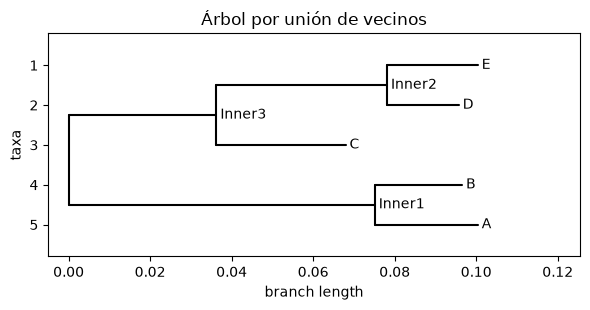

In [4]:
from Bio.Phylo.TreeConstruction import DistanceMatrix, DistanceTreeConstructor
from Bio import Phylo
import matplotlib.pyplot as plt

names = list(species)
def p_distance(a, b):
    aln = aligner.align(a, b)[0]
    s1, s2 = aln[0], aln[1]
    pairs = [(x, y) for x, y in zip(s1, s2) if x != "-" and y != "-"]
    return sum(x != y for x, y in pairs) / len(pairs)

matrix = [[p_distance(species[names[i]], species[names[j]]) for j in range(i)] + [0.0] for i in range(len(names))]
dm = DistanceMatrix(names, matrix)
print(dm)
tree = DistanceTreeConstructor().nj(dm)
tree.root_at_midpoint()
fig, ax = plt.subplots(figsize=(6, 3.2))
Phylo.draw(tree, axes=ax, do_show=False); ax.set_title("Árbol por unión de vecinos"); plt.tight_layout(); plt.show()

## 4. Análisis de supervivencia en un ensayo real de cáncer de mama
**GBSG2** (German Breast Cancer Study Group, 686 pacientes) siguió a mujeres después de la cirugía y registró
el tiempo hasta que el cáncer reapareció (`time`, en días) o hasta que terminó el seguimiento sin recaída
(`cens = 0`, una observación *censurada*). Ignorar la censura sesga cualquier media, y por eso el análisis de
supervivencia tiene sus propios métodos.

La pregunta del ensayo: **¿alarga la terapia hormonal (`horTh`) la supervivencia libre de recaída?**

In [5]:
from lifelines.datasets import load_gbsg2
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test

gb = load_gbsg2()
print(gb.shape); print(gb["horTh"].value_counts().to_dict(), "| eventos (recaídas):", int(gb["cens"].sum()))
gb.head()

(686, 10)
{'no': 440, 'yes': 246} | eventos (recaídas): 299


,horTh,age,menostat,tsize,tgrade,pnodes,progrec,estrec,time,cens
0,no,70,Post,21,II,3,48,66,1814,1
1,yes,56,Post,12,II,7,61,77,2018,1
2,yes,58,Post,35,II,9,52,271,712,1
3,yes,59,Post,17,II,4,60,29,1807,1
4,no,73,Post,35,II,1,26,65,772,1


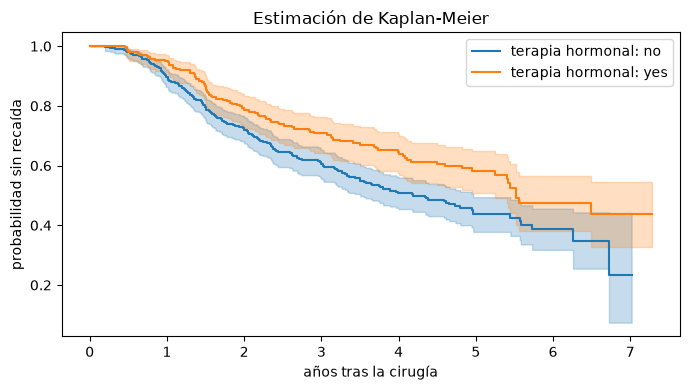

valor p de la prueba log-rank: 0.0034


In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for group, d in gb.groupby("horTh"):
    KaplanMeierFitter(label=f"terapia hormonal: {group}").fit(d["time"] / 365.25, d["cens"]).plot_survival_function(ax=ax)
ax.set_xlabel("años tras la cirugía"); ax.set_ylabel("probabilidad sin recaída"); ax.set_title("Estimación de Kaplan-Meier")
plt.tight_layout(); plt.show()

yes, no = gb[gb.horTh == "yes"], gb[gb.horTh == "no"]
test = logrank_test(yes["time"], no["time"], event_observed_A=yes["cens"], event_observed_B=no["cens"])
print(f"valor p de la prueba log-rank: {test.p_value:.4f}")

Las curvas se separan y la prueba log-rank indica que la diferencia difícilmente se debe al azar. Pero las
pacientes tratadas y no tratadas pueden diferir en otras cosas (edad, tamaño del tumor, ganglios linfáticos).
La **regresión de riesgos proporcionales de Cox** estima el efecto de la terapia ajustando por ellas; un
cociente de riesgos (hazard ratio) menor que 1 significa menos riesgo de recaída.

In [7]:
X = gb.assign(horTh=(gb.horTh == "yes").astype(int), menostat=(gb.menostat == "Post").astype(int),
              tgrade=gb.tgrade.map({"I": 1, "II": 2, "III": 3}))
cph = CoxPHFitter().fit(X[["time", "cens", "horTh", "age", "menostat", "tsize", "tgrade", "pnodes", "progrec", "estrec"]],
                        duration_col="time", event_col="cens")
cph.print_summary(columns=["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"], decimals=3)

<lifelines.CoxPHFitter: fitted with 686 total observations, 387 right-censored observations>
             duration col = 'time'
                event col = 'cens'
      baseline estimation = breslow
   number of observations = 686
number of events observed = 299
   partial log-likelihood = -1737.174
         time fit was run = 2026-10-18 10:11:34 UTC

---
          exp(coef) exp(coef) lower 95% exp(coef) upper 95%       p
covariate                                                          
horTh         0.714               0.554               0.919   0.009
age           0.991               0.973               1.009   0.311
menostat      1.306               0.912               1.871   0.145
tsize         1.008               1.000               1.016   0.051
tgrade        1.324               1.075               1.629   0.008
pnodes        1.051               1.036               1.067 <0.0005
progrec       0.998               0.997               0.999 <0.0005
estrec        1.000               0.999               1.001   0.708
---
Concordance = 0.688
Partial AIC = 3490.349
log-likelihood ratio test = 101.860 on 8 df
-log2(p) of ll-ratio test = 58.965

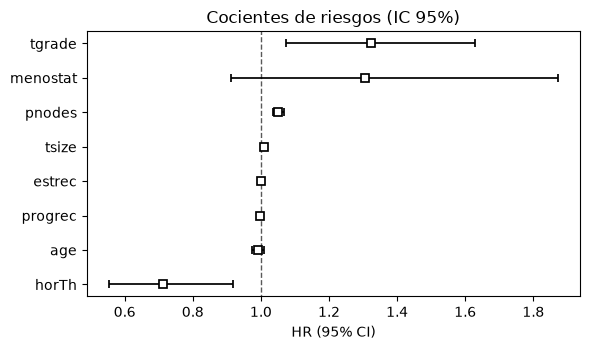

Ajustando por los demás factores, la terapia hormonal multiplica el riesgo de recaída por 0.71 (alrededor de un 29% menos). Más ganglios positivos y un grado tumoral mayor lo aumentan.


In [8]:
fig, ax = plt.subplots(figsize=(6, 3.6))
cph.plot(hazard_ratios=True, ax=ax); ax.set_title("Cocientes de riesgos (IC 95%)"); plt.tight_layout(); plt.show()
hr = cph.hazard_ratios_["horTh"]
print(f"Ajustando por los demás factores, la terapia hormonal multiplica el riesgo de recaída por {hr:.2f} "
      f"(alrededor de un {100 * (1 - hr):.0f}% menos). Más ganglios positivos y un grado tumoral mayor lo aumentan.")

## 5. Un clasificador de diagnóstico
El conjunto de datos de cáncer de mama de Wisconsin (incluido en scikit-learn) describe núcleos celulares de
569 biopsias, cada una etiquetada como maligna o benigna. En el diagnóstico los dos errores no pesan igual: no
detectar un tumor maligno (falso negativo) es mucho peor que una falsa alarma, así que elegimos el umbral de
decisión pensando en la **sensibilidad**, no en la exactitud.

AUC ROC con validación cruzada: 0.996
umbral 0.524: sensibilidad 0.958, especificidad 0.997, malignos no detectados 9, falsas alarmas 1
umbral 0.085: sensibilidad 0.995, especificidad 0.868, malignos no detectados 1, falsas alarmas 47


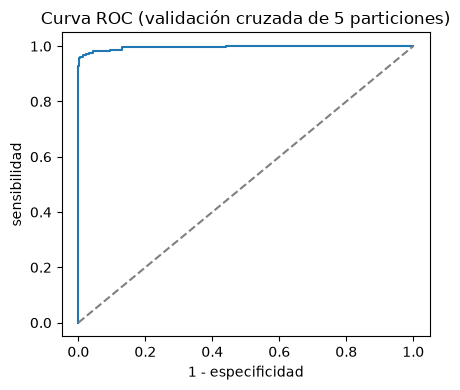

In [9]:
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

data = load_breast_cancer()
y = (data.target == 0).astype(int)                  # 1 = maligno
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.5))
proba = cross_val_predict(model, data.data, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
print(f"AUC ROC con validación cruzada: {roc_auc_score(y, proba):.3f}")

fpr, tpr, thr = roc_curve(y, proba)
for target_sens in (0.95, 0.99):
    i = next(k for k, t in enumerate(tpr) if t >= target_sens)
    tn, fp, fn, tp = confusion_matrix(y, proba >= thr[i]).ravel()
    print(f"umbral {thr[i]:.3f}: sensibilidad {tp / (tp + fn):.3f}, especificidad {tn / (tn + fp):.3f}, "
          f"malignos no detectados {fn}, falsas alarmas {fp}")

plt.figure(figsize=(4.5, 4)); plt.plot(fpr, tpr); plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("1 - especificidad"); plt.ylabel("sensibilidad"); plt.title("Curva ROC (validación cruzada de 5 particiones)"); plt.tight_layout(); plt.show()

## Bibliotecas que conviene conocer en este campo
| Área | Bibliotecas |
|---|---|
| secuencias, archivos, bases de datos | Biopython, scikit-bio, pysam (alineamientos genómicos) |
| célula única y ómicas | Scanpy, AnnData |
| estructura de proteínas | Biopython PDB, MDAnalysis; las predicciones de AlphaFold se distribuyen como archivos que estas leen |
| imagen médica | pydicom, SimpleITK, MONAI (aprendizaje profundo) |
| supervivencia y estadística clínica | lifelines, scikit-survival, statsmodels |
| epidemiología | epipy, modelos compartimentales con SciPy (`solve_ivp`) |

## Ejercicios
1. Aumenta el número de mutaciones de la simulación hasta que la unión de vecinos se equivoque de árbol. ¿Cuánta divergencia aguanta?
2. Estratifica las curvas de Kaplan-Meier por grado del tumor (`tgrade`) en lugar de por terapia.
3. Sustituye la regresión logística por gradient boosting en el modelo de diagnóstico. ¿Mejora el AUC y compensa la pérdida de interpretabilidad?